# Mixed 调度在长输入在线负载中的作用
## 长输入在线实验 · 两个到达种子 · 三个执行 block

**结论：mixed 的主要价值是减少开始输出后的长停顿、缩短请求完成时间；高负载下还有吞吐收益，但需要付出更长的首 token 等待。**

本报告仅使用已经完成的 长输入在线实验 数据，不新增推理实验。主要基线为 **separate**，interleaved 为辅助对照。所有计算由下方 Python 单元格从公开测量 JSON 完整重算，图像由 Matplotlib 生成。

> **证据边界**：这是同一套完整 SPEED-Bench 长文本上的合成 Poisson 到达实验，不是生产流量回放。所有配置均出现跨策略输出哈希不一致，因此性能观察不能直接扩展为“答案等价且全面更优”。

阅读顺序：数据核验 → 总体权衡 → 配对收益 → 生成停顿 → 延迟构成与积压 → 结论边界。

## 1. 数据来源与复现

数据目录：`reports/data/long_input_serving/formal`。

Notebook 已嵌入执行结果，打开即可阅读。重新运行时，在本仓库中使用项目 `.venv` Python 内核；需要 `numpy、matplotlib、IPython`。从当前目录向上自动寻找仓库，不依赖远程机绝对路径。代码仅读取结果并写出图像，不加载模型。

统计单位为一次完整回放。每个“速率 × 到达种子 × budget × 策略”有三个 block；100 条请求不被当作 100 次独立实验。

公开版保留全部逐请求测量及策略汇总；输入 token 序列仅保留长度和 SHA-256，重复的顶层 summary 已移除。此处能重算性能报告，不能直接用于推理回放。导出规则和原始文件指纹见 [数据说明](../data/README.md)。

In [1]:
%matplotlib inline
import json, math, statistics as st, itertools, hashlib
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'reports/data/long_input_serving/formal').is_dir())
FORMAL = ROOT / 'reports/data/long_input_serving/formal'
FIGURES = ROOT / 'reports/long_input_serving/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.sans-serif'] = [f for f in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans'] if f in fonts]
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 120,
                     'savefig.dpi': 170, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
COLORS = {'separate': '#64748b', 'interleaved': '#d59627', 'mixed': '#087f8c'}
POLICIES = ['separate', 'interleaved', 'mixed']
BLOCKS = [0, 3, 4]
RATES = [0.5, 0.75, 1.0]
SEEDS = [20261012, 20261013]
def read(p): return json.loads(p.read_text(encoding='utf-8-sig'))
def table(headers, body):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---']*len(headers)) + ' |\n' +
                     '\n'.join('| ' + ' | '.join(map(str, r)) + ' |' for r in body)))
def finish(fig, name):
    fig.savefig(FIGURES / (name + '.png'), bbox_inches='tight')
    plt.show()

In [2]:
schedule = read(FORMAL / 'schedule.json')
assert schedule['block_ids'] == BLOCKS
assert read(FORMAL / 'blocks.json')['entries'] == schedule['entries']
expected_cases = {(rate, seed, budget) for rate in RATES for seed in SEEDS for budget in [384, 512]}
rows, identities, traces, text_sets, hashes = [], defaultdict(set), {}, set(), []
raw = {}
for entry in schedule['entries']:
    case = Path(entry['config']).stem
    path = FORMAL / f"block{entry['block']}" / case / 'results.json'
    d = read(path)
    assert d['status'] == 'complete'
    assert d['settings']['warmup'] == d['settings']['rounds'] == 1
    assert d['settings']['token_budget'] == entry['token_budget']
    assert tuple(r['policy'] for r in d['runs']) == list(itertools.permutations(POLICIES))[entry['block']]
    for k in ['source_sha256', 'environment', 'checkpoint_files']:
        identities[k].add(json.dumps(d[k], sort_keys=True))
    trace = d['trace']; generation = trace['generation']
    rate, seed, budget = generation['arrival_rate'], generation['seed'], entry['token_budget']
    key = (rate, seed)
    if key in traces: assert trace == traces[key]
    traces[key] = trace
    text_sets.add(json.dumps([{k:v for k,v in q.items() if k != 'arrival_s'} for q in trace['requests']], sort_keys=True))
    specs = {q['id']: q for q in trace['requests']}
    assert len(specs) == len(trace['requests']) == 100
    hashes.append(d['matching_outputs'])
    for run in d['runs']:
        requests = sorted(run['requests'], key=lambda q:q['arrival_s'])
        assert len(requests) == len({q['id'] for q in requests}) == 100
        assert {q['id'] for q in requests} == set(specs)
        for q in requests:
            assert q['output_tokens'] == specs[q['id']]['max_tokens'] == 128
            assert q['arrival_s'] == specs[q['id']]['arrival_s']
            assert q['arrival_s'] <= q['admission_s'] <= q['first_token_s'] <= q['last_token_s']
            assert math.isclose(q['e2e_ms'], q['ttft_ms'] + 127*q['tpot_ms'], abs_tol=1e-6)
        s = run['summary']; g = run['online']['groups']['all']
        assert math.isclose(s['elapsed_s']*s['output_tok_s'], 12800, abs_tol=1e-6)
        for m in ['ttft_ms', 'e2e_ms', 'tpot_ms']:
            assert math.isclose(st.mean(q[m] for q in requests), s[m]['mean'], abs_tol=1e-6)
        row = dict(rate=rate, seed=seed, budget=budget, block=entry['block'], policy=run['policy'],
                   case=case, source=str(path.relative_to(FORMAL)),
                   throughput=s['output_tok_s'], ttft=s['ttft_ms']['mean']/1000,
                   e2e=s['e2e_ms']['mean']/1000, e2e95=s['e2e_ms']['p95']/1000,
                   decode=127*s['tpot_ms']['mean']/1000, itl95=s['itl_ms']['p95'],
                   stall95=g['max_itl_ms']['p95'], preemptions=s['counts']['preemptions'],
                   mixed_fraction=s['mixed_step_fraction'], steps=s['counts']['steps'],
                   drain=max(q['last_token_s'] for q in requests)-max(q['arrival_s'] for q in requests))
        assert all(math.isfinite(row[m]) for m in ['throughput','ttft','e2e','e2e95','decode','itl95','stall95','drain'])
        rows.append(row)
        raw[rate,seed,budget,entry['block'],run['policy']] = requests
index = {(r['rate'],r['seed'],r['budget'],r['block'],r['policy']):r for r in rows}
assert len(index) == len(rows) == 108
assert set(index) == {(rate,seed,budget,b,p) for rate,seed,budget in expected_cases for b in BLOCKS for p in POLICIES}
assert all(len(v)==1 for v in identities.values()) and len(text_sets)==1
lengths = [q['input_tokens'] for q in trace['requests']]
env = d['environment']
table(['核验项','结果'], [
    ['完整结果文件 / 正式回放 / 请求记录', f"{len(hashes)} / {len(rows)} / {sum(len(v) for v in raw.values())}"],
    ['到达种子 / block', f'{SEEDS} / {BLOCKS}'],
    ['速率 / token budget', f'{RATES} req/s / 384、512'],
    ['独立文本集合 / 输入长度', f'{len(text_sets)} / {min(lengths)}–{max(lengths)} token'],
    ['文本类别', str(dict(Counter(q['category'] for q in trace['provenance'])))],
    ['模型 / GPU / dtype', f"{d['settings']['model']} / {env['gpu']} / {d['settings']['dtype']}"],
    ['每批最大序列数 / KV blocks / prefix cache', f"{d['settings']['max_seqs']} / {d['settings']['blocks']} / {d['settings']['prefix_cache']}"],
    ['源码 / 环境 / 模型指纹种类', str({k:len(v) for k,v in identities.items()})],
    ['输出哈希跨策略不一致文件', f'{sum(not v for v in hashes)} / {len(hashes)}'],
    ['重复、缺失组合、非有限核心指标、数值恒等式', '全部检查通过；未删除异常记录']])
def values(rate, seed, budget, policy, metric):
    return np.array([index[rate,seed,budget,b,policy][metric] for b in BLOCKS])
def mean(rate, seed, budget, policy, metric):
    return float(values(rate,seed,budget,policy,metric).mean())
def change(rate, seed, budget, metric, baseline='separate'):
    a=mean(rate,seed,budget,baseline,metric); b=mean(rate,seed,budget,'mixed',metric)
    return 100*(b/a-1)

| 核验项 | 结果 |
| --- | --- |
| 完整结果文件 / 正式回放 / 请求记录 | 36 / 108 / 10800 |
| 到达种子 / block | [20261012, 20261013] / [0, 3, 4] |
| 速率 / token budget | [0.5, 0.75, 1.0] req/s / 384、512 |
| 独立文本集合 / 输入长度 | 1 / 1941–2171 token |
| 文本类别 | {'high_entropy': 50, 'low_entropy': 50} |
| 模型 / GPU / dtype | /root/model/Qwen3-4B / NVIDIA GeForce RTX 4090 / bfloat16 |
| 每批最大序列数 / KV blocks / prefix cache | 16 / 565 / False |
| 源码 / 环境 / 模型指纹种类 | {'source_sha256': 1, 'environment': 1, 'checkpoint_files': 1} |
| 输出哈希跨策略不一致文件 | 36 / 36 |
| 重复、缺失组合、非有限核心指标、数值恒等式 | 全部检查通过；未删除异常记录 |

## 2. 吞吐、完成时间和首 token 的权衡

每条线代表一个策略；实线为种子 20261012，虚线为 20261013，点为三个 block 的均值。两个种子分开展示，不把到达流量差异隐藏在总平均里。

**阅读重点**：低速率时吞吐接近，仍然可能有完成延迟收益；高负载时 mixed 的吞吐提高，但首 token 等待也更长。这里的吞吐包含等待到达及末尾排空，不等于最大稳态容量。

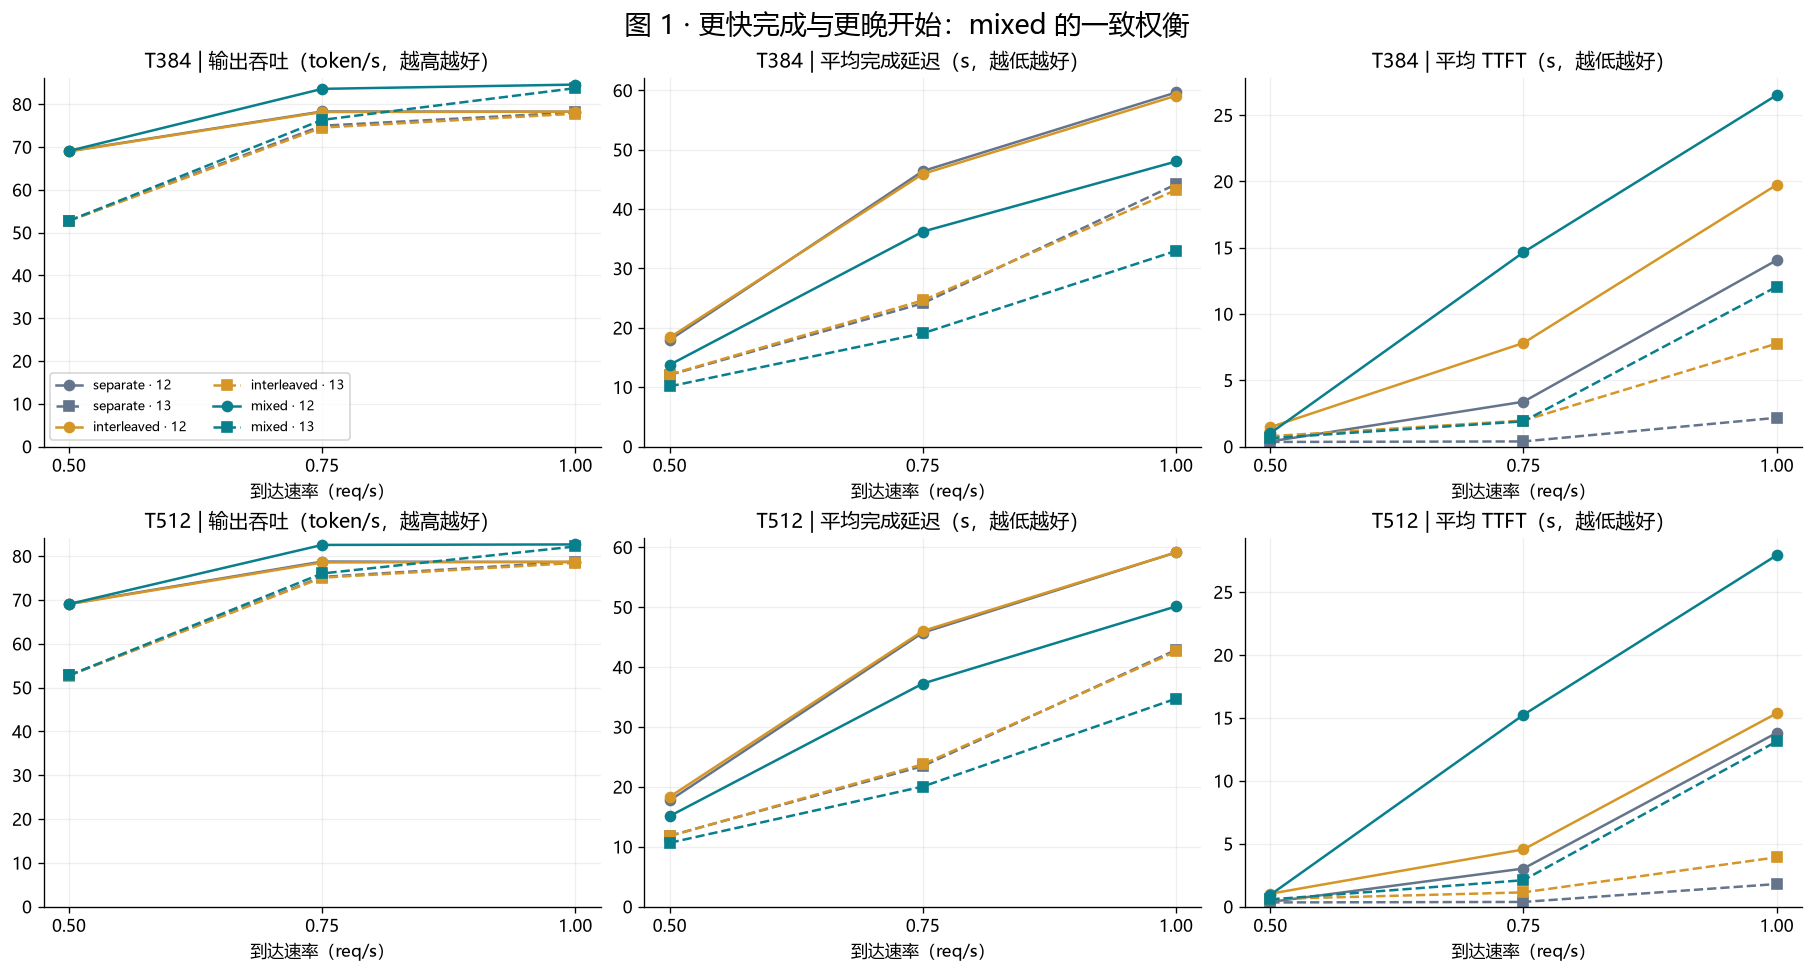

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for i,budget in enumerate([384,512]):
    for j,(metric,label) in enumerate([('throughput','输出吞吐（token/s，越高越好）'),('e2e','平均完成延迟（s，越低越好）'),('ttft','平均 TTFT（s，越低越好）')]):
        ax=axes[i,j]
        for policy in POLICIES:
            for seed,ls,marker in [(SEEDS[0],'-','o'),(SEEDS[1],'--','s')]:
                ax.plot(RATES,[mean(rate,seed,budget,policy,metric) for rate in RATES],color=COLORS[policy],linestyle=ls,marker=marker,label=f'{policy} · {str(seed)[-2:]}')
        ax.set(title=f'T{budget} | {label}',xlabel='到达速率（req/s）',xticks=RATES)
        ax.grid(alpha=.2); ax.set_ylim(bottom=0)
axes[0,0].legend(fontsize=8,ncol=2)
fig.suptitle('图 1 · 更快完成与更晚开始：mixed 的一致权衡', fontsize=16)
finish(fig,'01_tradeoff')

## 3. 全部配置的配对收益

下图将收益统一为“正值更好”：吞吐使用 `(mixed / separate − 1) × 100%`；延迟使用 `(1 − mixed / separate) × 100%`。先对三个 block 求均值，再计算比值，不混合不同配置。

颜色区间固定在 ±100%，超出范围用深色封顶；**格内文字仍显示真实百分比**。TTFT 的大幅负值是代价，不能忽略。

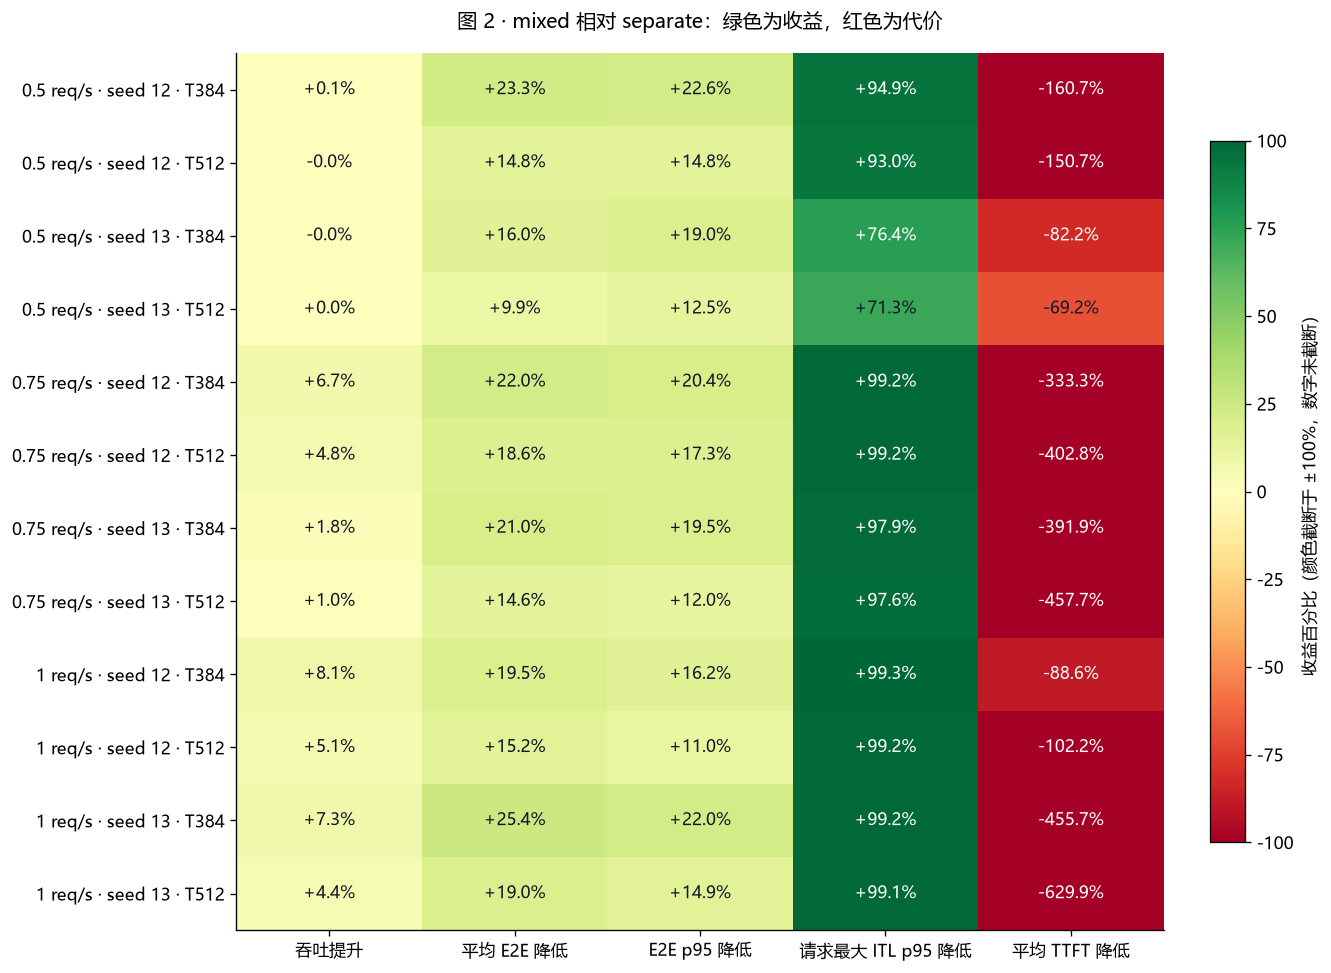

| 指标 | mixed 胜出的配对数 | 配对差 95% t 区间完全位于有利方向的配置数 |
| --- | --- | --- |
| throughput | 30/36 | 9/12 |
| e2e | 36/36 | 12/12 |
| e2e95 | 36/36 | 12/12 |
| stall95 | 36/36 | 12/12 |
| ttft | 0/36 | 0/12 |

In [4]:
cases=sorted(expected_cases)
metrics=['throughput','e2e','e2e95','stall95','ttft']
benefit=np.array([[change(*c,m)*(1 if m=='throughput' else -1) for m in metrics] for c in cases])
fig,ax=plt.subplots(figsize=(11,8),layout='constrained')
im=ax.imshow(benefit,cmap='RdYlGn',vmin=-100,vmax=100,aspect='auto')
ax.set_xticks(range(5),['吞吐提升','平均 E2E 降低','E2E p95 降低','请求最大 ITL p95 降低','平均 TTFT 降低'])
ax.set_yticks(range(len(cases)),[f'{rate:g} req/s · seed {str(seed)[-2:]} · T{budget}' for rate,seed,budget in cases])
for i in range(len(cases)):
    for j in range(5):
        ax.text(j,i,f'{benefit[i,j]:+.1f}%',ha='center',va='center',color='white' if abs(benefit[i,j])>75 else '#111827',fontsize=10)
ax.set_title('图 2 · mixed 相对 separate：绿色为收益，红色为代价',pad=15)
fig.colorbar(im,ax=ax,label='收益百分比（颜色截断于 ±100%，数字未截断）',shrink=.8)
finish(fig,'02_paired_benefits')

body=[]
for metric in metrics:
    deltas=[index[*c,b,'mixed'][metric]-index[*c,b,'separate'][metric] for c in cases for b in BLOCKS]
    wins=sum(v>0 if metric=='throughput' else v<0 for v in deltas)
    intervals=[]
    for c in cases:
        ds=values(*c,'mixed',metric)-values(*c,'separate',metric)
        half=4.302652729911275*st.stdev(ds)/math.sqrt(3)
        intervals.append((float(ds.mean()-half),float(ds.mean()+half)))
    favorable=sum(lo>0 if metric=='throughput' else hi<0 for lo,hi in intervals)
    body.append([metric,f'{wins}/36',f'{favorable}/12'])
table(['指标','mixed 胜出的配对数','配对差 95% t 区间完全位于有利方向的配置数'],body)

**解释**：平均 E2E、E2E p95 和请求最大 ITL 的 p95 在全部配对中改善；平均 TTFT 在全部配对中恶化。高负载吞吐收益跨 block 一致，低负载吞吐差异很小。

区间使用三个 block 的配对差、df=2，反映重复执行的波动。它们是探索性、未经多重比较校正的区间；不能将两种到达种子下的重复视为多个独立文本集合。

## 4. mixed 减少的是什么卡顿？

**普通 ITL p95** 对所有输出 token 间隔取分位数；**请求最大 ITL 的 p95** 则先找每个请求最慢的一次间隔，再对 100 个请求取 p95。后者突出少数很长的生成停顿，二者不可混用，也都不包含首 token 前的等待。

下图显示全部正式回放的点：每个“速率 × 策略”包含两个种子、三个 block，不绘制跨种子伪置信区间。左图采用对数坐标以同时展示毫秒级和秒级停顿。

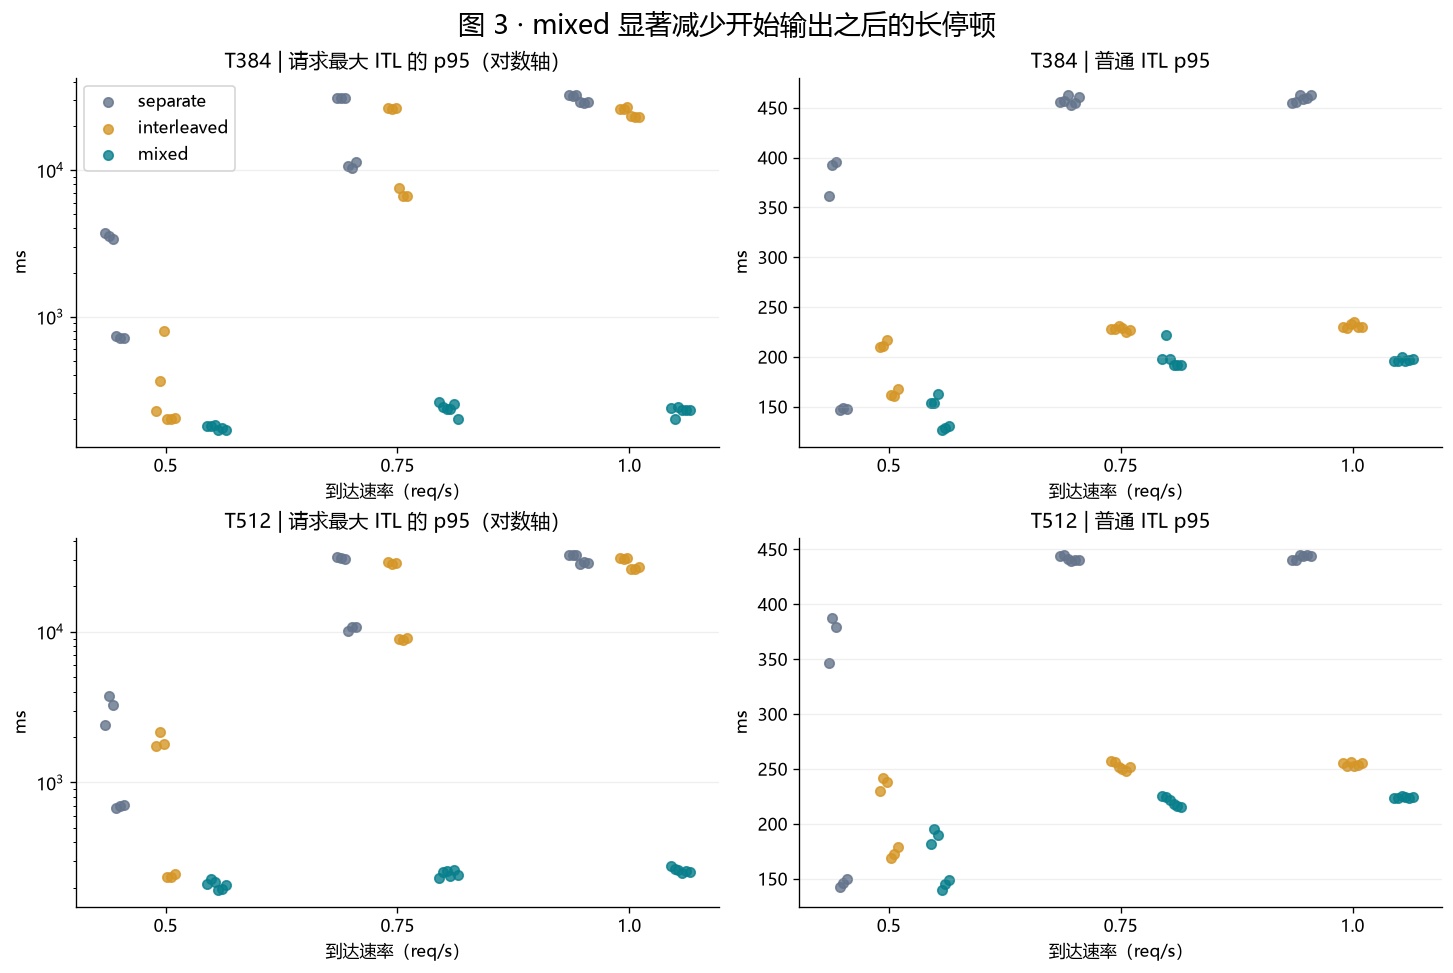

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for i,budget in enumerate([384,512]):
    for j,metric in enumerate(['stall95','itl95']):
        ax=axes[i,j]
        for ri,rate in enumerate(RATES):
            for pi,policy in enumerate(POLICIES):
                xs=[];ys=[]
                for si,seed in enumerate(SEEDS):
                    for bi,b in enumerate(BLOCKS):
                        xs.append(ri+(pi-1)*.22+(si*3+bi-2.5)*.016)
                        ys.append(index[rate,seed,budget,b,policy][metric])
                ax.scatter(xs,ys,color=COLORS[policy],s=32,alpha=.8,label=policy if ri==0 else None)
        ax.set_xticks(range(3),RATES);ax.set_xlabel('到达速率（req/s）');ax.set_ylabel('ms')
        ax.set_title(f'T{budget} | '+('请求最大 ITL 的 p95（对数轴）' if j==0 else '普通 ITL p95'))
        if j==0: ax.set_yscale('log')
        ax.grid(alpha=.2,axis='y')
axes[0,0].legend()
fig.suptitle('图 3 · mixed 显著减少开始输出之后的长停顿',fontsize=16)
finish(fig,'03_generation_stalls')

高负载下，separate 的“请求最大 ITL 的 p95”达到数十秒，而 mixed 在这些回放中保持在数百毫秒量级。这支持“输出更连续”，不能表述为“整体响应快了 99%”。

低负载、无抢占的配置中同样能看到停顿改善，所以全部收益不能仅用“避免抢占”解释。

## 5. 首 token 更慢，为什么完成反而更快？

固定输出 128 token 时，每个请求满足：

$$\mathrm{E2E}=\mathrm{TTFT}+127\times\mathrm{TPOT}$$

这里选择共同的高负载 `1.0 req/s、T384`，同时展示两个种子；每根柱为三个 block 的均值。浅色为 TTFT，深色为首 token 后的生成时间。

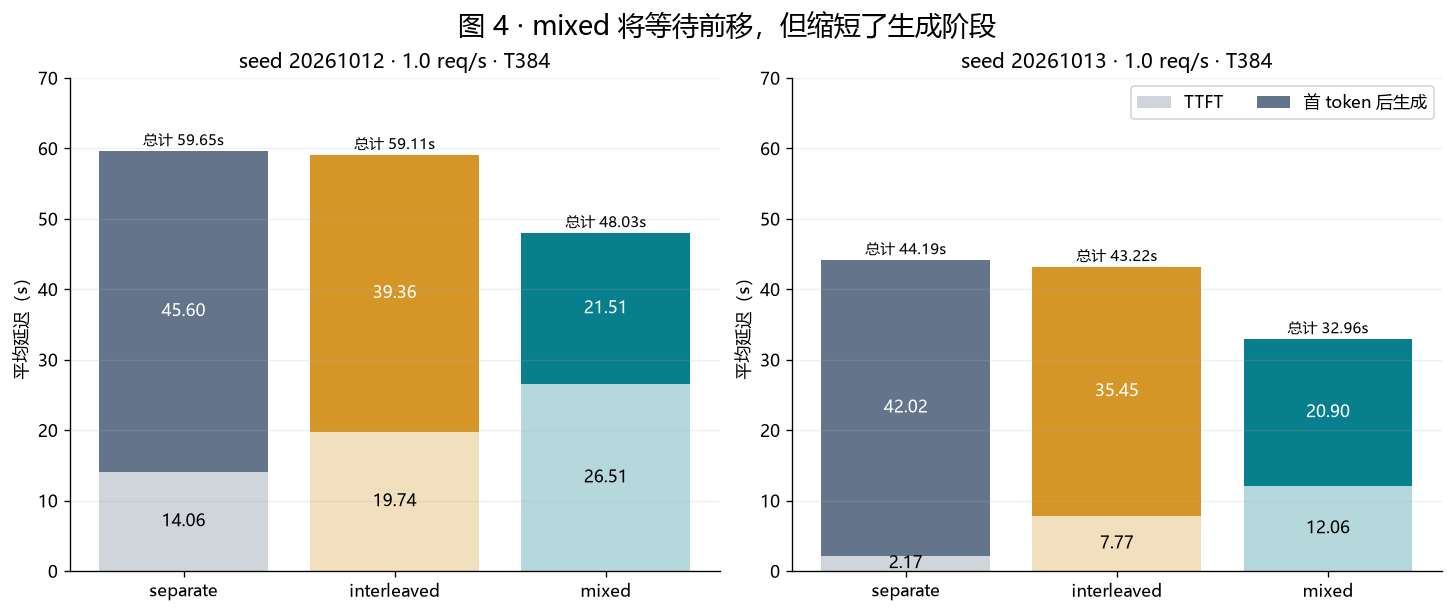

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,seed in zip(axes,SEEDS):
    for i,policy in enumerate(POLICIES):
        first=mean(1.0,seed,384,policy,'ttft'); after=mean(1.0,seed,384,policy,'decode')
        ax.bar(i,first,color=COLORS[policy],alpha=.3,label='TTFT' if i==0 else None)
        ax.bar(i,after,bottom=first,color=COLORS[policy],label='首 token 后生成' if i==0 else None)
        ax.text(i,first/2,f'{first:.2f}',ha='center',va='center')
        ax.text(i,first+after/2,f'{after:.2f}',ha='center',va='center',color='white')
        ax.text(i,first+after+.8,f'总计 {first+after:.2f}s',ha='center',fontsize=9)
    ax.set(xticks=range(3),xticklabels=POLICIES,ylabel='平均延迟（s）',title=f'seed {seed} · 1.0 req/s · T384',ylim=(0,70))
    ax.grid(axis='y',alpha=.2)
axes[1].legend(loc='upper right', ncol=2)
fig.suptitle('图 4 · mixed 将等待前移，但缩短了生成阶段',fontsize=16)
finish(fig,'04_latency_decomposition')

以种子 20261012 为例：separate 平均 TTFT 为 14.06 s、后续生成 45.60 s；mixed 为 26.51 s 和 21.51 s，总完成时间从 59.65 s 降至 48.03 s。

代码中的 separate 优先 prefill；mixed 先安排 decode，再把剩余 token 和批次名额交给 prefill。这与“保护生成连续性、推迟新请求首 token”的现象一致。现有数据尚不能独立量化合批前向、调度优先级和资源占用各自的贡献。

## 6. 积压与资源行为

下面用逐请求时间戳重建“已到达但尚未完成”的请求数。它包含等待与正在运行的请求，**不是调度器 waiting 队列长度**。

固定 `1.0 req/s、T384`，两种子均展示三个 block 的范围（阴影）及均值（曲线）；虚线标记最后一次请求到达。

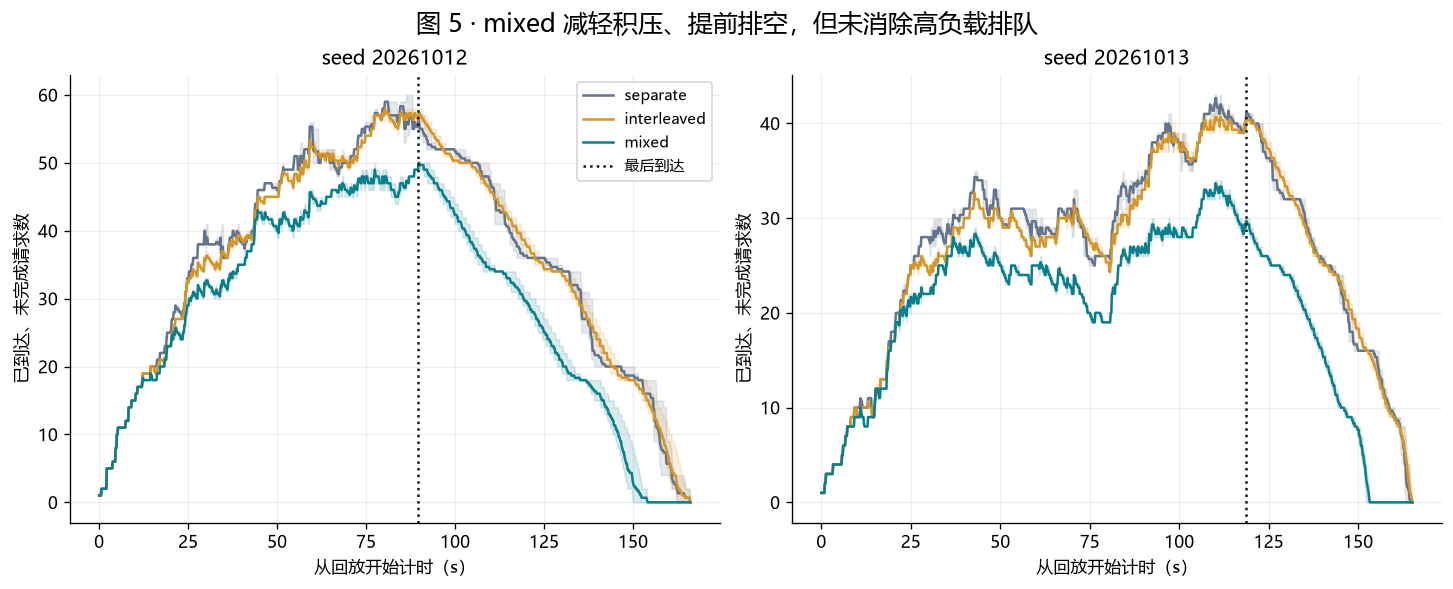

| 策略 | 全部正式回放中的抢占总次数 | 发生抢占的回放数 | mixed step 占比范围 |
| --- | --- | --- | --- |
| separate | 27 | 16 | 0.0%–0.0% |
| interleaved | 8 | 5 | 0.0%–0.0% |
| mixed | 0 | 0 | 11.1%–60.3% |

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,seed in zip(axes,SEEDS):
    end=max(q['last_token_s'] for p in POLICIES for b in BLOCKS for q in raw[1.0,seed,384,b,p])
    grid=np.linspace(0,end,1000)
    for policy in POLICIES:
        curves=[]
        for b in BLOCKS:
            qs=raw[1.0,seed,384,b,policy]
            curves.append([sum(q['arrival_s']<=t<q['last_token_s'] for q in qs) for t in grid])
        curves=np.array(curves)
        ax.plot(grid,curves.mean(axis=0),color=COLORS[policy],label=policy)
        ax.fill_between(grid,curves.min(axis=0),curves.max(axis=0),color=COLORS[policy],alpha=.15)
    last=max(q['arrival_s'] for q in raw[1.0,seed,384,0,'separate'])
    ax.axvline(last,color='#111827',linestyle=':',label='最后到达')
    ax.set(title=f'seed {seed}',xlabel='从回放开始计时（s）',ylabel='已到达、未完成请求数')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=9)
fig.suptitle('图 5 · mixed 减轻积压、提前排空，但未消除高负载排队',fontsize=15)
finish(fig,'05_backlog')
table(['策略','全部正式回放中的抢占总次数','发生抢占的回放数','mixed step 占比范围'],[
    [p,sum(r['preemptions'] for r in rows if r['policy']==p),
     sum(r['preemptions']>0 for r in rows if r['policy']==p),
     f"{min(r['mixed_fraction'] for r in rows if r['policy']==p):.1%}–{max(r['mixed_fraction'] for r in rows if r['policy']==p):.1%}"] for p in POLICIES])

mixed 实际产生了 prefill/decode 合批，并且本次正式回放没有抢占。separate 与 interleaved 存在抢占，因此高负载性能差异同时包含调度、资源接纳和重算影响；不能将全部吞吐差异直接归因为 GPU 合批效率。

在本次数据中，mixed/T384 的平均 E2E 在六个“速率 × 种子”组合中均低于 mixed/T512，可作为当前配置下更偏向生成连续性的选择。它不是已经证明的全局最优预算，低负载下其 TTFT 也可能略差。

## 7. 全配置数值表与辅助基线

下表保留两个种子和两个 budget，不把它们混为一个总分。每项原始值都是三个 block 的均值，箭头为 separate → mixed。E2E 与 TTFT 单位为秒。

In [8]:
body=[]
for c in cases:
    vals=[]
    for m in ['throughput','e2e','ttft','stall95']:
        vals.append(f"{mean(*c,'separate',m):.2f} → {mean(*c,'mixed',m):.2f}")
    body.append([f'{c[0]:g}/{c[1]}/T{c[2]}',*vals,f"{change(*c,'e2e'):+.2f}%",f"{mean(*c,'mixed','throughput')/mean(*c,'separate','throughput'):.4f}×"])
table(['速率/种子/budget','吞吐 tok/s','E2E s','TTFT s','请求最大 ITL p95 ms','E2E 变化','吞吐比'],body)

body=[]
for c in cases:
    body.append([f'{c[0]:g}/{c[1]}/T{c[2]}',*[f"{change(*c,m,baseline='interleaved'):+.2f}%" for m in ['throughput','e2e','ttft']]])
display(Markdown('### 辅助对照：mixed 相对 interleaved（正值表示指标增加）'))
table(['速率/种子/budget','吞吐变化','平均 E2E 变化','平均 TTFT 变化'],body)

| 速率/种子/budget | 吞吐 tok/s | E2E s | TTFT s | 请求最大 ITL p95 ms | E2E 变化 | 吞吐比 |
| --- | --- | --- | --- | --- | --- | --- |
| 0.5/20261012/T384 | 69.05 → 69.09 | 17.95 → 13.77 | 0.39 → 1.01 | 3546.22 → 180.38 | -23.26% | 1.0006× |
| 0.5/20261012/T512 | 69.10 → 69.07 | 17.74 → 15.12 | 0.38 → 0.94 | 3138.54 → 219.17 | -14.76% | 0.9996× |
| 0.5/20261013/T384 | 52.79 → 52.78 | 12.06 → 10.14 | 0.35 → 0.63 | 722.62 → 170.89 | -15.96% | 0.9997× |
| 0.5/20261013/T512 | 52.78 → 52.78 | 11.83 → 10.66 | 0.34 → 0.57 | 696.86 → 199.80 | -9.87% | 1.0002× |
| 0.75/20261012/T384 | 78.32 → 83.61 | 46.41 → 36.21 | 3.38 → 14.66 | 30926.98 → 246.11 | -21.97% | 1.0675× |
| 0.75/20261012/T512 | 78.77 → 82.57 | 45.75 → 37.26 | 3.03 → 15.25 | 30778.63 → 247.88 | -18.57% | 1.0482× |
| 0.75/20261013/T384 | 74.99 → 76.35 | 24.14 → 19.08 | 0.39 → 1.90 | 10798.72 → 229.77 | -20.97% | 1.0182× |
| 0.75/20261013/T512 | 75.27 → 76.05 | 23.48 → 20.06 | 0.38 → 2.11 | 10512.34 → 248.46 | -14.55% | 1.0104× |
| 1/20261012/T384 | 78.26 → 84.61 | 59.65 → 48.03 | 14.06 → 26.51 | 32548.71 → 227.58 | -19.50% | 1.0811× |
| 1/20261012/T512 | 78.65 → 82.68 | 59.15 → 50.13 | 13.82 → 27.93 | 32189.78 → 270.37 | -15.24% | 1.0512× |
| 1/20261013/T384 | 78.10 → 83.77 | 44.19 → 32.96 | 2.17 → 12.06 | 29040.05 → 230.99 | -25.40% | 1.0727× |
| 1/20261013/T512 | 78.74 → 82.22 | 42.87 → 34.73 | 1.80 → 13.14 | 28663.22 → 254.87 | -18.99% | 1.0442× |

### 辅助对照：mixed 相对 interleaved（正值表示指标增加）

| 速率/种子/budget | 吞吐变化 | 平均 E2E 变化 | 平均 TTFT 变化 |
| --- | --- | --- | --- |
| 0.5/20261012/T384 | +0.15% | -25.03% | -31.02% |
| 0.5/20261012/T512 | +0.05% | -17.55% | -8.49% |
| 0.5/20261013/T384 | +0.04% | -16.40% | -19.18% |
| 0.5/20261013/T512 | +0.07% | -9.48% | -5.84% |
| 0.75/20261012/T384 | +6.92% | -21.15% | +87.57% |
| 0.75/20261012/T512 | +5.10% | -19.07% | +235.13% |
| 0.75/20261013/T384 | +2.41% | -22.55% | -3.10% |
| 0.75/20261013/T512 | +1.28% | -15.64% | +85.09% |
| 1/20261012/T384 | +8.10% | -18.75% | +34.28% |
| 1/20261012/T512 | +5.01% | -15.25% | +81.73% |
| 1/20261013/T384 | +7.69% | -23.73% | +55.29% |
| 1/20261013/T512 | +4.79% | -18.49% | +234.82% |

相对 interleaved，mixed 的平均 E2E 也在全部配对中改善，但 TTFT 收益不是普遍成立：低负载下通常改善，高负载下经常恶化。它进一步支持“完成速度与生成连续性”的定位，而非“所有延迟指标同时改善”。

## 8. 可以写入结论的发现与限制

**有数据支持的发现**

1. 在本次约 2K token 长输入、固定 128 token 输出的在线回放中，mixed 相对 separate 一致缩短了平均和 p95 完成延迟，并减少了生成长停顿。
2. 1.0 req/s 下，四个“种子 × budget”配置的吞吐提升约 4.42%–8.11%；低速率下吞吐基本不变，延迟仍有改善。
3. 收益伴随一致的 TTFT 代价。mixed 更适合重视生成连续性与总完成时间的目标；是否适合具体交互服务，需要结合首 token 的实际约束，当前没有预设 SLO，不能声称 SLO goodput 改善。
4. 两个种子、三个 block 的一致方向增强了本工作负载上的重复性证据，但没有扩大文本集合覆盖范围。

**必须保留的限制**

- 全部 36 个文件跨策略输出哈希不一致；同策略跨 block 也存在差异。哈希按请求 ID 排序计算，不是简单的完成顺序差异。可能涉及 BF16、批次变化或实现问题，现有记录不能确定原因；固定输出长度不代表输出质量等价。
- 同一套 100 条文本、固定长度输出、合成 Poisson 到达、单模型单 GPU：不能直接推广到更长上下文、不同输出分布或生产流量。
- 有限回放中的吞吐不是稳态容量，TTFT/ITL 不包含 HTTP 和网络开销。
- 未保存完整 step 细节和生成 token，不能单独归因 GPU 合批效率，也不能进行答案等价性诊断。

> **最终结论**：现有 长输入在线实验 结果已经展示了 mixed 在长输入在线调度中的性能作用：它通过优先推进已开始生成的请求，改善输出连续性和完成延迟，并在高负载下带来吞吐收益；同时延后新请求的首 token。该结论限于当前工作负载和实现，不能扩展为输出等价前提下的全面优势。

本报告到此仅解释已有结果，不启动或要求追加实验。

## 附录：原始记录定位

`rate0/1/2` 分别对应 `0.5/0.75/1.0 req/s`。每份文件包含三策略；引用指标时使用文件路径加 `runs` 中的策略名。

In [9]:
table(['配置','block','原始记录'],[[Path(e['config']).stem,e['block'],
    f"block{e['block']}/{Path(e['config']).stem}/results.json"] for e in schedule['entries']])
print('所有图像目录：', FIGURES.relative_to(ROOT).as_posix())
print('原始数据只读，未运行模型或新增实验。')

| 配置 | block | 原始记录 |
| --- | --- | --- |
| E_rate0_seed20261012_T384 | 0 | block0/E_rate0_seed20261012_T384/results.json |
| E_rate0_seed20261012_T512 | 0 | block0/E_rate0_seed20261012_T512/results.json |
| E_rate0_seed20261013_T384 | 0 | block0/E_rate0_seed20261013_T384/results.json |
| E_rate0_seed20261013_T512 | 0 | block0/E_rate0_seed20261013_T512/results.json |
| E_rate1_seed20261012_T384 | 0 | block0/E_rate1_seed20261012_T384/results.json |
| E_rate1_seed20261012_T512 | 0 | block0/E_rate1_seed20261012_T512/results.json |
| E_rate1_seed20261013_T384 | 0 | block0/E_rate1_seed20261013_T384/results.json |
| E_rate1_seed20261013_T512 | 0 | block0/E_rate1_seed20261013_T512/results.json |
| E_rate2_seed20261012_T384 | 0 | block0/E_rate2_seed20261012_T384/results.json |
| E_rate2_seed20261012_T512 | 0 | block0/E_rate2_seed20261012_T512/results.json |
| E_rate2_seed20261013_T384 | 0 | block0/E_rate2_seed20261013_T384/results.json |
| E_rate2_seed20261013_T512 | 0 | block0/E_rate2_seed20261013_T512/results.json |
| E_rate0_seed20261013_T512 | 3 | block3/E_rate0_seed20261013_T512/results.json |
| E_rate1_seed20261012_T384 | 3 | block3/E_rate1_seed20261012_T384/results.json |
| E_rate1_seed20261012_T512 | 3 | block3/E_rate1_seed20261012_T512/results.json |
| E_rate1_seed20261013_T384 | 3 | block3/E_rate1_seed20261013_T384/results.json |
| E_rate1_seed20261013_T512 | 3 | block3/E_rate1_seed20261013_T512/results.json |
| E_rate2_seed20261012_T384 | 3 | block3/E_rate2_seed20261012_T384/results.json |
| E_rate2_seed20261012_T512 | 3 | block3/E_rate2_seed20261012_T512/results.json |
| E_rate2_seed20261013_T384 | 3 | block3/E_rate2_seed20261013_T384/results.json |
| E_rate2_seed20261013_T512 | 3 | block3/E_rate2_seed20261013_T512/results.json |
| E_rate0_seed20261012_T384 | 3 | block3/E_rate0_seed20261012_T384/results.json |
| E_rate0_seed20261012_T512 | 3 | block3/E_rate0_seed20261012_T512/results.json |
| E_rate0_seed20261013_T384 | 3 | block3/E_rate0_seed20261013_T384/results.json |
| E_rate1_seed20261012_T384 | 4 | block4/E_rate1_seed20261012_T384/results.json |
| E_rate1_seed20261012_T512 | 4 | block4/E_rate1_seed20261012_T512/results.json |
| E_rate1_seed20261013_T384 | 4 | block4/E_rate1_seed20261013_T384/results.json |
| E_rate1_seed20261013_T512 | 4 | block4/E_rate1_seed20261013_T512/results.json |
| E_rate2_seed20261012_T384 | 4 | block4/E_rate2_seed20261012_T384/results.json |
| E_rate2_seed20261012_T512 | 4 | block4/E_rate2_seed20261012_T512/results.json |
| E_rate2_seed20261013_T384 | 4 | block4/E_rate2_seed20261013_T384/results.json |
| E_rate2_seed20261013_T512 | 4 | block4/E_rate2_seed20261013_T512/results.json |
| E_rate0_seed20261012_T384 | 4 | block4/E_rate0_seed20261012_T384/results.json |
| E_rate0_seed20261012_T512 | 4 | block4/E_rate0_seed20261012_T512/results.json |
| E_rate0_seed20261013_T384 | 4 | block4/E_rate0_seed20261013_T384/results.json |
| E_rate0_seed20261013_T512 | 4 | block4/E_rate0_seed20261013_T512/results.json |

所有图像目录： reports/long_input_serving/figures
原始数据只读，未运行模型或新增实验。
